# Experiment 9 — Run a Regression Model: Predict Student Marks
**EoAI 2026–27 | CO6 | Google Colab**

**Aim:** Use five subject marks to predict a percentage with linear regression and interpret the results.

**First:** File → **Save a copy in Drive**. Rename your personal copy `EoAI_Exp09_StudentID_Name.ipynb` using your actual ID and name.

**Dataset note:** This repository contains **synthetic** marks and simulated IDs only, not current students’ real grades. The percentage is based on the mean of the marks with slight variation, so a high R² is expected by construction. This is a learning example, not a real academic decision model.

**Evidence to submit in your Google Doc:** (1) dataset preview/features/target, (2) actual vs predicted percentages plus MSE and R², (3) actual-versus-predicted scatter plot. Add 2–3 lines of observation.

## Step 1 — Import libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
print("Libraries loaded successfully.")

Libraries loaded successfully.


## Step 2 — Load the academic-year synthetic dataset and inspect columns

In [2]:
url = "https://raw.githubusercontent.com/swarupjoys/ai-labs/main/EoAI-I/2026-27/datasets/student_marks_synthetic.csv"
df = pd.read_csv(url)
features = [f"Subject_{i}" for i in range(1, 6)]
target = "Percentage"
print("DATASET PREVIEW (SYNTHETIC RECORDS)")
print(df.head(8).to_string(index=False))
print("\nFeatures:", features)
print("Target:", target)
print("Total records:", len(df))

DATASET PREVIEW (SYNTHETIC RECORDS)
Sample_ID  Subject_1  Subject_2  Subject_3  Subject_4  Subject_5  Percentage
   SIM001         73         72         35         80         91        71.2
   SIM002         93         95         71         90         81        86.3
   SIM003         48         73         52         83         38        57.3
   SIM004         77         61         53         60         44        57.9
   SIM005         69         85         92         65         83        80.8
   SIM006         39         67         33         40         31        41.8
   SIM007         30         41         51         77         62        51.5
   SIM008         73         53         65         30         81        61.4

Features: ['Subject_1', 'Subject_2', 'Subject_3', 'Subject_4', 'Subject_5']
Target: Percentage
Total records: 90


## Step 3 — Split into training and test sets

In [3]:
X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))

Training rows: 72 | Test rows: 18


## Step 4 — Fit a Linear Regression model and predict

In [4]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Model trained and test predictions generated.")

Model trained and test predictions generated.


## Step 5 — Compare actual and predicted values; report MSE and R²

In [5]:
results = pd.DataFrame({"Actual Percentage": y_test.to_numpy(), "Predicted Percentage": y_pred})
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("ACTUAL VS PREDICTED PERCENTAGE")
print(results.head(10).round(2).to_string(index=False))
print("\nMean Squared Error (MSE):", round(mse, 4))
print("R² Score:", round(r2, 4))

ACTUAL VS PREDICTED PERCENTAGE
 Actual Percentage  Predicted Percentage
              91.3                 90.35
              62.6                 61.43
              68.2                 67.90
              68.5                 67.61
              71.2                 70.03
              56.0                 56.24
              62.2                 61.78
              45.3                 46.48
              73.7                 76.24
              67.5                 69.27

Mean Squared Error (MSE): 1.8842
R² Score: 0.9792


## Step 6 — Actual vs Predicted scatter plot

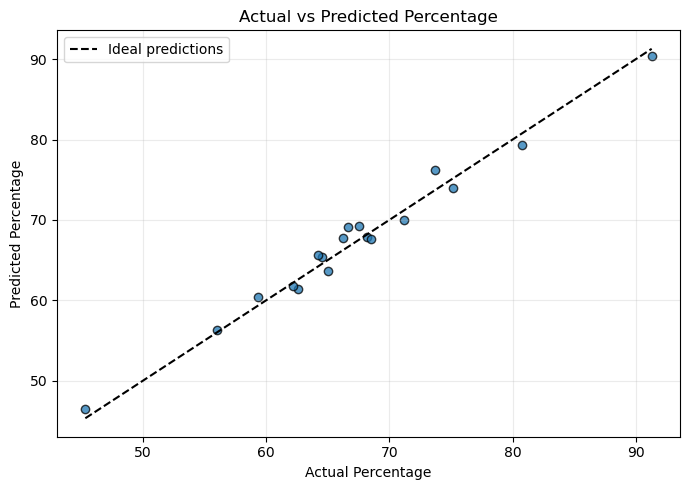

In [6]:
plt.figure(figsize=(7,5))
plt.scatter(y_test, y_pred, edgecolors="black", alpha=0.75)
lo = min(float(y_test.min()), float(y_pred.min()))
hi = max(float(y_test.max()), float(y_pred.max()))
plt.plot([lo,hi],[lo,hi],"k--",label="Ideal predictions")
plt.xlabel("Actual Percentage")
plt.ylabel("Predicted Percentage")
plt.title("Actual vs Predicted Percentage")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## Step 7 — Optional: Make a personalized example prediction

Replace `YourFirstName` with **your own first name or Student ID** and change the five **hypothetical** marks to see your predicted percentage. The values stay in your personal Colab copy and are **not added to the public dataset**. This is not a prediction of your real grades.

In [7]:
name_or_id = "YourFirstName"
sample_marks = [70, 75, 68, 80, 77]  # Replace with five hypothetical scores
assert len(sample_marks) == 5 and all(0 <= v <= 100 for v in sample_marks)
new_row = pd.DataFrame([sample_marks], columns=features)
print(f"Example prediction for {name_or_id}: {model.predict(new_row)[0]:.2f}%")

Example prediction for YourFirstName: 74.25%


## Result / Observation

Write 2–3 lines describing the five features, the target percentage, the observed MSE/R² values, and how close the scatter points are to the diagonal line. Add your **three screenshots** on a new Experiment 9 page of your existing Google Doc. Save your Colab copy.